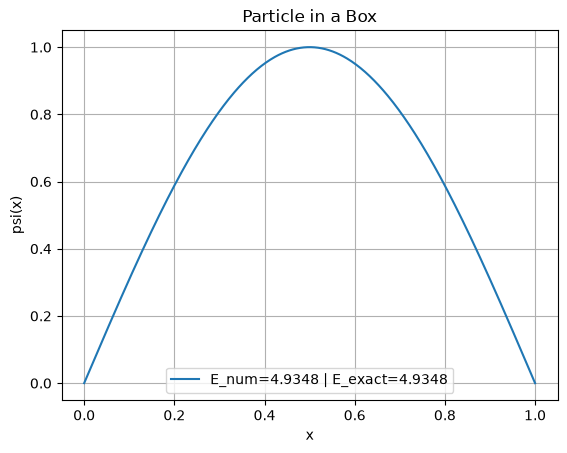

In [ ]:
#PARTICLE IN A BOX
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 1.0, 500)
dx = x[1] - x[0]

# RK4 integrator for d2psi/dx2 = -2*E*psi
def rk4(E):
    psi, dpsi = np.zeros(len(x)), np.zeros(len(x)) #Creates two NumPy arrays filled with zeros, each having the same length as the grid array
    #psi stores the value of the wavefunction psi(x) at each spatial point & dpsi stores the value of the first derivative at each spatial point.
    dpsi[0] = 1.0  # Initial boundary condition: psi(0)=0, slope=1
    
    for i in range(len(x) - 1): #It calculates the next step (i + 1) from the current step (i)
        f = lambda y1: -2.0 * E * y1
                                                # ooupled rk4  for first order derivative 
        k1_v, k1_y = f(psi[i]), dpsi[i]
        k2_v, k2_y = f(psi[i] + 0.5 * dx * k1_y), dpsi[i] + 0.5 * dx * k1_v
        k3_v, k3_y = f(psi[i] + 0.5 * dx * k2_y), dpsi[i] + 0.5 * dx * k2_v
        k4_v, k4_y = f(psi[i] + dx * k3_y), dpsi[i] + dx * k3_v
        
        dpsi[i+1] = dpsi[i] + (dx / 6.0) * (k1_v + 2*k2_v + 2*k3_v + k4_v)
        psi[i+1] = psi[i] + (dx / 6.0) * (k1_y + 2*k2_y + 2*k3_y + k4_y)
        
    return psi

# Secant method to find root 
E1, E2 = 3.0, 5.0  # initial guess
# say f(E) = psi(L;E) , we need to look for a root where this f(E) becomes 0
for _ in range(30):
    f1, f2 = rk4(E1)[-1], rk4(E2)[-1]   
    if abs(f2 - f1) < 10**-(12):    #   to prevent division by 0
        break
    E_next = E2 - f2 * (E2 - E1) / (f2 - f1) # predict next possible value 
    E1, E2 = E2, E_next   # shifting values for next iteration 


psi = rk4(E2)
plt.plot(x, psi / np.max(np.abs(psi)), label=f"E_num={E2:.4f} | E_exact={np.pi**2/2:.4f}")
plt.title("Particle in a Box")
plt.xlabel("x")
plt.ylabel("psi(x)")
plt.legend()
plt.grid(True)
plt.show()

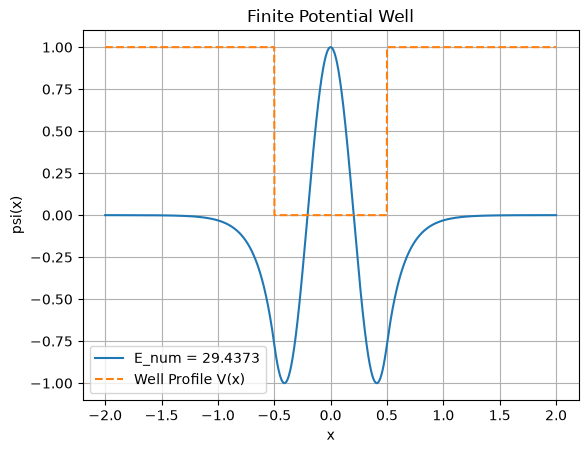

In [ ]:
# FINITE POTENTIAL WELL
import matplotlib.pyplot as plt
import numpy as np

# Physical constants and domain setup (in atomic units \hbar = m = 1)
V0 = 50.0  # Well depth
a = 0.5  # Half-width of the well (well spans [-a, a])
L = 2.0  # Grid boundary extending into the barrier region [0, L]

# Integrate on [0, L] to exploit parity symmetry and prevent exponential divergence
x_half = np.linspace(0, L, 1000)
dx = x_half[1] - x_half[0]


def V(x_val):
    return 0.0 if abs(x_val) <= a else V0


def rk4(E):
    psi, dpsi = np.zeros(len(x_half)), np.zeros(len(x_half))

    # Initial conditions at x = 0 for Ground State (Even Parity)
    psi[0] = 1.0  # Non-zero value at x = 0
    dpsi[0] = 0.0  # Slope is zero at x = 0

    for i in range(len(x_half) - 1):
        xi = x_half[i]

        #
        f = lambda x_val, y1: 2.0 * (V(x_val) - E) * y1

        # RK4 intermediate evaluations at x, x + dx/2, and x + dx
        k1_v = f(xi, psi[i])
        k1_y = dpsi[i]

        k2_v = f(xi + 0.5 * dx, psi[i] + 0.5 * dx * k1_y)
        k2_y = dpsi[i] + 0.5 * dx * k1_v

        k3_v = f(xi + 0.5 * dx, psi[i] + 0.5 * dx * k2_y)
        k3_y = dpsi[i] + 0.5 * dx * k2_v

        k4_v = f(xi + dx, psi[i] + dx * k3_y)
        k4_y = dpsi[i] + dx * k3_v

        dpsi[i + 1] = dpsi[i] + (dx / 6) * (k1_v + 2 * k2_v + 2 * k3_v + k4_v)
        psi[i + 1] = psi[i] + (dx / 6) * (k1_y + 2 * k2_y + 2 * k3_y + k4_y)

    return psi


# Secant root finding for boundary condition psi(L) = 0
E1, E2 = 10.0, 15.0
for _ in range(30):
    f1, f2 = rk4(E1)[-1], rk4(E2)[-1]
    if abs(f2 - f1) < 1e-12:
        break
    E_next = E2 - f2 * (E2 - E1) / (f2 - f1)
    E1, E2 = E2, E_next

# Construct full [-L, L] solution for plotting
psi_right = rk4(E2)
psi = np.concatenate((psi_right[::-1], psi_right[1:]))
x = np.linspace(-L, L, len(psi))
V_full = np.array([V(xi) for xi in x])

# Plotting
plt.plot(x, psi / np.max(np.abs(psi)), label=f"E_num = {E2:.4f}")
plt.plot(x, V_full / V0, "--", label="Well Profile V(x)")
plt.title("Finite Potential Well")
plt.xlabel("x")
plt.ylabel("psi(x)")
plt.legend()
plt.grid(True)
plt.show()

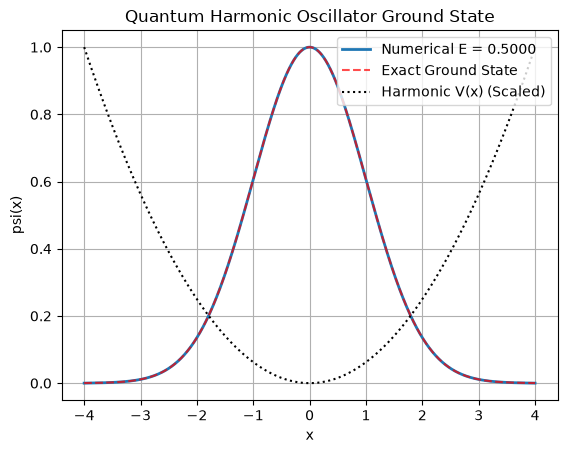

In [22]:
#HARMONIC POTENTIAL
import matplotlib.pyplot as plt
import numpy as np

# Physical constants and domain setup (in atomic units \hbar = m = 1)
omega = 1.0  # Oscillator frequency
L = 4.0  # Boundary extending into classically forbidden region [0, L]

# Integrate on [0, L] to exploit parity symmetry
x_half = np.linspace(0, L, 1000)
dx = x_half[1] - x_half[0]


def V(x_val):
    return 0.5 * (omega**2) * (x_val**2)


def rk4(E):
    psi, dpsi = np.zeros(len(x_half)), np.zeros(len(x_half))

    # Initial conditions at x = 0 for Ground State (Even Parity)
    psi[0] = 1.0  # Non-zero value at x = 0
    dpsi[0] = 0.0  # Slope is zero at x = 0

    for i in range(len(x_half) - 1):
        xi = x_half[i]

        # Schrödinger ODE: d2psi/dx2 = 2 * (V(x) - E) * psi
        f = lambda x_val, y1: 2.0 * (V(x_val) - E) * y1

        # RK4 intermediate evaluations
        k1_v = f(xi, psi[i])
        k1_y = dpsi[i]

        k2_v = f(xi + 0.5 * dx, psi[i] + 0.5 * dx * k1_y)
        k2_y = dpsi[i] + 0.5 * dx * k1_v

        k3_v = f(xi + 0.5 * dx, psi[i] + 0.5 * dx * k2_y)
        k3_y = dpsi[i] + 0.5 * dx * k2_v

        k4_v = f(xi + dx, psi[i] + dx * k3_y)
        k4_y = dpsi[i] + dx * k3_v

        dpsi[i + 1] = dpsi[i] + (dx / 6) * (k1_v + 2 * k2_v + 2 * k3_v + k4_v)
        psi[i + 1] = psi[i] + (dx / 6) * (k1_y + 2 * k2_y + 2 * k3_y + k4_y)

    return psi


# Secant root finding for boundary condition psi(L) = 0
E1, E2 = 0.2, 0.8
for _ in range(30):
    f1, f2 = rk4(E1)[-1], rk4(E2)[-1]
    if abs(f2 - f1) < 1e-12:
        break
    E_next = E2 - f2 * (E2 - E1) / (f2 - f1)
    E1, E2 = E2, E_next

# Construct full [-L, L] solution for plotting
psi_right = rk4(E2)
psi = np.concatenate((psi_right[::-1], psi_right[1:]))
x = np.linspace(-L, L, len(psi))
V_full = np.array([V(xi) for xi in x])

# Normalized numerical solution
psi_norm = psi / np.max(np.abs(psi))

# Analytical solution for ground state ground state psi_0(x) = exp(-x^2 / 2)
psi_exact = np.exp(-(x**2) / 2.0)

# Plotting
plt.plot(x, psi_norm, label=f"Numerical E = {E2:.4f}", linewidth=2)
plt.plot(x, psi_exact, "r--", label="Exact Ground State", alpha=0.7)
plt.plot(x, V_full / np.max(V_full), "k:", label="Harmonic V(x) (Scaled)")

plt.title("Quantum Harmonic Oscillator Ground State")
plt.xlabel("x")
plt.ylabel("psi(x)")
plt.legend()
plt.grid(True)
plt.show()